# Assignment 5(b) - Bayes Classification on the Given Dataset (group 14)

The data is supplied as `x, y, class label` in two files (`trian.txt`, 1050 points and `dev.txt`,
300 points; 3 classes, 450 points each in total). The two files are pooled into one set of 1350 points,
80% is used to estimate the parameters by **maximum likelihood** and the remaining 20% is classified.


In [ ]:
import math
import random
import numpy as np
import matplotlib.pyplot as plt

random.seed(7)

## 1. Load the data

In [ ]:
def load(path):
    pts, labels = [], []
    for line in open(path):
        line = line.strip()
        if not line:
            continue
        a, b, c = line.split(",")
        pts.append([float(a), float(b)])
        labels.append(int(c))
    return pts, labels


px1, pl1 = load("trian.txt")
px2, pl2 = load("dev.txt")
points = px1 + px2
labels = pl1 + pl2

K = max(labels)
print(f"total points: {len(points)}   classes: {K}")
for c in range(1, K + 1):
    print(f"  class {c}: {labels.count(c)} points")

total points: 1350   classes: 3
  class 1: 450 points
  class 2: 450 points
  class 3: 450 points


## 2. Matrix utilities and the maximum likelihood estimators

For a Gaussian the ML estimates are
$$\hat{\mu} = \frac{1}{n}\sum_k x_k, \qquad \hat{\Sigma} = \frac{1}{n}\sum_k (x_k-\hat{\mu})(x_k-\hat{\mu})^T,$$
so the covariance is normalised by $n$ (not $n-1$, which is the unbiased estimator).

In [ ]:
def det2(A):
    return A[0][0] * A[1][1] - A[0][1] * A[1][0]


def inv2(A):
    d = det2(A)
    if abs(d) < 1e-20:
        raise ValueError("singular matrix")
    return [[ A[1][1] / d, -A[0][1] / d],
            [-A[1][0] / d,  A[0][0] / d]]


def eig_sym2(A):
    a, b, d = A[0][0], A[0][1], A[1][1]
    if abs(b) < 1e-12:                      # already diagonal
        if a >= d:
            return [a, d], [[1.0, 0.0], [0.0, 1.0]]
        return [d, a], [[0.0, 1.0], [1.0, 0.0]]
    tr, det = a + d, a * d - b * b
    disc = math.sqrt(max(tr * tr / 4.0 - det, 0.0))
    l1, l2 = tr / 2.0 + disc, tr / 2.0 - disc
    vecs = []
    for lam in (l1, l2):
        v = [lam - d, b]
        n = math.hypot(v[0], v[1])
        vecs.append([v[0] / n, v[1] / n])
    return [l1, l2], vecs


def ml_mean(X):
    n = len(X)
    return [sum(p[0] for p in X) / n, sum(p[1] for p in X) / n]


def ml_cov(X, mu):
    """Maximum likelihood covariance: normalised by n."""
    n = len(X)
    s00 = s01 = s11 = 0.0
    for p in X:
        d0, d1 = p[0] - mu[0], p[1] - mu[1]
        s00 += d0 * d0
        s01 += d0 * d1
        s11 += d1 * d1
    return [[s00 / n, s01 / n], [s01 / n, s11 / n]]

## 3. 80 / 20 split, stratified by class

In [ ]:
def split_by_class(points, labels, K, frac=0.8):
    train = [[] for _ in range(K)]
    test = [[] for _ in range(K)]
    for c in range(K):
        pts = [p for p, l in zip(points, labels) if l == c + 1]
        idx = list(range(len(pts)))
        random.shuffle(idx)
        cut = int(frac * len(pts))
        train[c] = [pts[i] for i in idx[:cut]]
        test[c] = [pts[i] for i in idx[cut:]]
    return train, test


train_sets, test_sets = split_by_class(points, labels, K, 0.8)
for c in range(K):
    print(f"class {c+1}: {len(train_sets[c])} train, {len(test_sets[c])} test")

class 1: 360 train, 90 test
class 2: 360 train, 90 test
class 3: 360 train, 90 test


## 4. Maximum likelihood models and the Bayes classifier

Three model families are fitted so their effect can be compared:

* **full** - each class keeps its own unconstrained $\Sigma_i$,
* **diagonal** - off-diagonal terms forced to zero,
* **isotropic** - $\Sigma_i = \sigma_i^2 I$ with $\sigma_i^2$ the average of the two variances.

The discriminant is $g_i(x) = -\tfrac12 (x-\mu_i)^T\Sigma_i^{-1}(x-\mu_i) - \tfrac12\ln|\Sigma_i| + \ln P(\omega_i)$,
with the priors taken from the training counts.

In [ ]:
def constrain(S, kind):
    if kind == "full":
        return [row[:] for row in S]
    if kind == "diagonal":
        return [[S[0][0], 0.0], [0.0, S[1][1]]]
    if kind == "isotropic":
        v = (S[0][0] + S[1][1]) / 2.0
        return [[v, 0.0], [0.0, v]]
    raise ValueError(kind)


def fit(train_sets, kind="full", shared=False):
    total = sum(len(t) for t in train_sets)
    mus = [ml_mean(T) for T in train_sets]
    covs = [ml_cov(T, m) for T, m in zip(train_sets, mus)]
    if shared:                      # pooled within-class covariance
        P = [[0.0, 0.0], [0.0, 0.0]]
        for T, S in zip(train_sets, covs):
            w = len(T) / total
            for i in range(2):
                for j in range(2):
                    P[i][j] += w * S[i][j]
        covs = [P for _ in covs]
    covs = [constrain(S, kind) for S in covs]
    return [{"mu": m, "Sigma": S, "inv": inv2(S), "logdet": math.log(det2(S)),
             "prior": len(T) / total}
            for m, S, T in zip(mus, covs, train_sets)]


def discriminant(m, x0, x1):
    d0, d1 = x0 - m["mu"][0], x1 - m["mu"][1]
    a, b, c = m["inv"][0][0], m["inv"][0][1], m["inv"][1][1]
    return (-0.5 * (a * d0 * d0 + 2.0 * b * d0 * d1 + c * d1 * d1)
            - 0.5 * m["logdet"] + math.log(m["prior"]))


def classify(models, x):
    best, best_s = 0, discriminant(models[0], x[0], x[1])
    for i in range(1, len(models)):
        s = discriminant(models[i], x[0], x[1])
        if s > best_s:
            best, best_s = i, s
    return best

In [ ]:
models = fit(train_sets, kind="full")

for i, m in enumerate(models):
    print(f"class {i+1}:  P(w{i+1}) = {m['prior']:.4f}")
    print(f"   mu_hat    = [{m['mu'][0]:10.3f}, {m['mu'][1]:10.3f}]")
    print(f"   Sigma_hat = [[{m['Sigma'][0][0]:12.2f}, {m['Sigma'][0][1]:12.2f}],")
    print(f"                [{m['Sigma'][1][0]:12.2f}, {m['Sigma'][1][1]:12.2f}]]")
    vals, vecs = eig_sym2(m["Sigma"])
    ang = math.degrees(math.atan2(vecs[0][1], vecs[0][0]))
    print(f"   eigenvalues = [{vals[0]:12.2f}, {vals[1]:10.2f}]   "
          f"axis lengths = [{math.sqrt(vals[0]):8.2f}, {math.sqrt(vals[1]):7.2f}]   "
          f"tilt = {ang:6.2f} deg")
    print(f"   correlation = {m['Sigma'][0][1]/math.sqrt(m['Sigma'][0][0]*m['Sigma'][1][1]):6.3f}\n")

class 1:  P(w1) = 0.3333
   mu_hat    = [   404.372,   1198.676]
   Sigma_hat = [[    20888.43,     31654.38],
                [    31654.38,    158277.62]]
   eigenvalues = [   165219.97,   13946.09]   axis lengths = [  406.47,  118.09]   tilt =  77.63 deg
   correlation =  0.551

class 2:  P(w2) = 0.3333
   mu_hat    = [   385.955,   1932.813]
   Sigma_hat = [[    18703.07,     -9768.20],
                [    -9768.20,     51145.53]]
   eigenvalues = [    53859.61,   15988.99]   axis lengths = [  232.08,  126.45]   tilt = -74.47 deg
   correlation = -0.316

class 3:  P(w3) = 0.3333
   mu_hat    = [   577.271,   1442.002]
   Sigma_hat = [[    21612.38,      2787.08],
                [     2787.08,     55540.69]]
   eigenvalues = [    55768.11,   21384.96]   axis lengths = [  236.15,  146.24]   tilt =  85.34 deg
   correlation =  0.080



## 5. Classify the held-out 20% and build the confusion matrix

In [ ]:
def confusion_matrix(models, test_sets):
    k = len(test_sets)
    M = [[0] * k for _ in range(k)]
    for true_i, T in enumerate(test_sets):
        for x in T:
            M[true_i][classify(models, x)] += 1
    return M


def print_confusion(M, title=""):
    k = len(M)
    total = sum(sum(r) for r in M)
    correct = sum(M[i][i] for i in range(k))
    if title:
        print(title)
    head = "true\\pred " + "".join(f"{'w'+str(j+1):>9}" for j in range(k)) + f"{'total':>8}{'recall':>9}"
    print(head)
    print("-" * len(head))
    for i in range(k):
        rs = sum(M[i])
        print(f"{'w'+str(i+1):<10}" + "".join(f"{M[i][j]:>9}" for j in range(k))
              + f"{rs:>8}{M[i][i]/rs:>9.4f}")
    print(f"{'precision':<10}" + "".join(
        f"{(M[j][j]/sum(M[i][j] for i in range(k)) if sum(M[i][j] for i in range(k)) else 0):>9.4f}"
        for j in range(k)))
    print(f"\noverall accuracy = {correct}/{total} = {correct/total:.4f}   "
          f"error rate = {1-correct/total:.4f}")
    return correct / total


M = confusion_matrix(models, test_sets)
acc_full = print_confusion(M, "Confusion matrix, full-covariance ML model, 20% test set\n"
                              "(rows = true class, columns = predicted class)\n")

Confusion matrix, full-covariance ML model, 20% test set
(rows = true class, columns = predicted class)

true\pred        w1       w2       w3   total   recall
------------------------------------------------------
w1               65        3       22      90   0.7222
w2                4       68       18      90   0.7556
w3                6        6       78      90   0.8667
precision    0.8667   0.8831   0.6610

overall accuracy = 211/270 = 0.7815   error rate = 0.2185


## 6. Decision boundaries with the test data overlaid

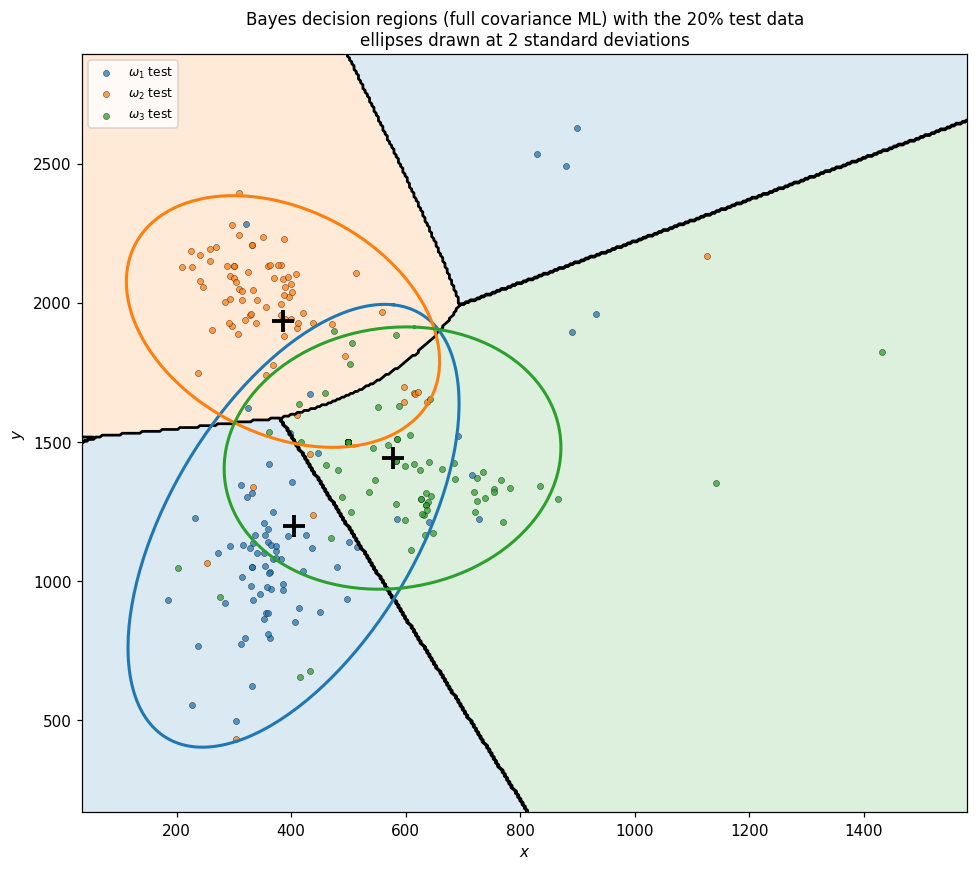

In [ ]:
COLORS = ["tab:blue", "tab:orange", "tab:green"]


def plot_case(models, test_sets, title, ax, show_train=None):
    pts = [p for T in test_sets for p in T]
    if show_train:
        pts = pts + [p for T in show_train for p in T]
    xs = [p[0] for p in pts]
    ys = [p[1] for p in pts]
    padx = 0.12 * (max(xs) - min(xs))
    pady = 0.12 * (max(ys) - min(ys))
    gx = np.linspace(min(xs) - padx, max(xs) + padx, 400)
    gy = np.linspace(min(ys) - pady, max(ys) + pady, 400)
    XX, YY = np.meshgrid(gx, gy)

    G = [discriminant(m, XX, YY) for m in models]
    region = np.zeros_like(XX)
    for i in range(1, len(G)):
        region = np.where(G[i] > np.maximum.reduce(G[:i]), i, region)

    ax.contourf(XX, YY, region, levels=[-0.5, 0.5, 1.5, 2.5], colors=COLORS, alpha=0.16)
    ax.contour(XX, YY, region, levels=[0.5, 1.5], colors="k", linewidths=1.8)

    th = np.linspace(0, 2 * np.pi, 240)
    for i, T in enumerate(test_sets):
        ax.scatter([p[0] for p in T], [p[1] for p in T], s=16, alpha=0.75,
                   color=COLORS[i], edgecolors="k", linewidths=0.3,
                   label=f"$\\omega_{i+1}$ test")
        m = models[i]
        ax.plot(m["mu"][0], m["mu"][1], "k+", markersize=14, mew=2.5)
        vals, vecs = eig_sym2(m["Sigma"])
        ex = m["mu"][0] + 2 * (math.sqrt(vals[0]) * vecs[0][0] * np.cos(th) +
                               math.sqrt(vals[1]) * vecs[1][0] * np.sin(th))
        ey = m["mu"][1] + 2 * (math.sqrt(vals[0]) * vecs[0][1] * np.cos(th) +
                               math.sqrt(vals[1]) * vecs[1][1] * np.sin(th))
        ax.plot(ex, ey, color=COLORS[i], lw=2)

    ax.set_title(title, fontsize=11)
    ax.set_xlabel("$x$")
    ax.set_ylabel("$y$")
    ax.legend(loc="upper left", fontsize=8)


fig, ax = plt.subplots(figsize=(9, 8))
plot_case(models, test_sets,
          "Bayes decision regions (full covariance ML) with the 20% test data\n"
          "ellipses drawn at 2 standard deviations", ax)
plt.tight_layout()
plt.show()

## 7. Comparison of the covariance models

In [ ]:
rows = []
for shared in (False, True):
    for kind in ("isotropic", "diagonal", "full"):
        mdl = fit(train_sets, kind=kind, shared=shared)
        a_tr = 1 - sum(1 for i, T in enumerate(train_sets) for x in T
                       if classify(mdl, x) != i) / sum(len(t) for t in train_sets)
        cm = confusion_matrix(mdl, test_sets)
        a_te = sum(cm[i][i] for i in range(K)) / sum(len(t) for t in test_sets)
        rows.append((("shared" if shared else "per-class"), kind, a_tr, a_te))

print(f"{'covariance':<12}{'type':<12}{'train acc':>11}{'test acc':>11}")
print("-" * 46)
for s, k, a, b in rows:
    print(f"{s:<12}{k:<12}{a:>11.4f}{b:>11.4f}")

covariance  type          train acc   test acc
----------------------------------------------
per-class   isotropic        0.7991     0.7667
per-class   diagonal         0.8102     0.7704
per-class   full             0.8157     0.7815
shared      isotropic        0.7815     0.7630
shared      diagonal         0.8056     0.7667
shared      full             0.8056     0.7667


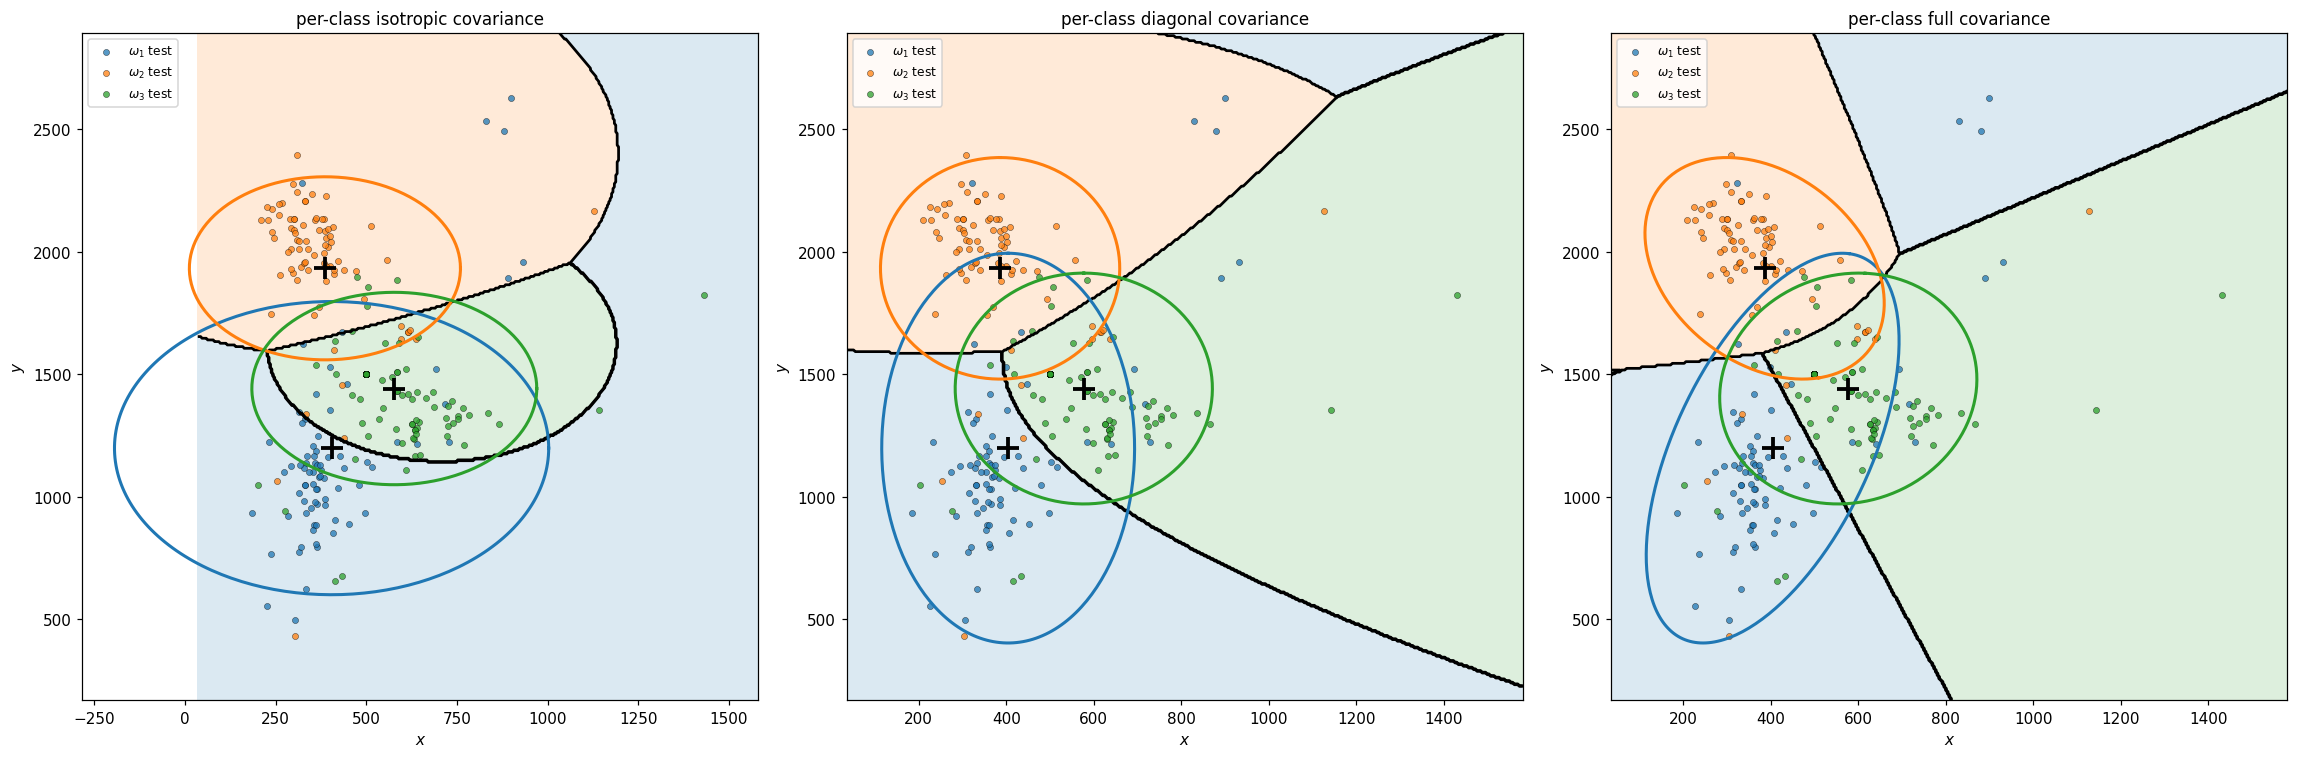

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(21, 7))
for ax, kind in zip(axes, ("isotropic", "diagonal", "full")):
    mdl = fit(train_sets, kind=kind)
    plot_case(mdl, test_sets, f"per-class {kind} covariance", ax)
plt.tight_layout()
plt.show()

## 8. Check against the supplied train / dev split

In [ ]:
train_given = [[p for p, l in zip(px1, pl1) if l == c + 1] for c in range(K)]
dev_given = [[p for p, l in zip(px2, pl2) if l == c + 1] for c in range(K)]
mdl_given = fit(train_given, kind="full")
print_confusion(confusion_matrix(mdl_given, dev_given),
                "Trained on trian.txt (1050 points), tested on dev.txt (300 points)\n")

Trained on trian.txt (1050 points), tested on dev.txt (300 points)

true\pred        w1       w2       w3   total   recall
------------------------------------------------------
w1               74        7       19     100   0.7400
w2                5       85       10     100   0.8500
w3                6        8       86     100   0.8600
precision    0.8706   0.8500   0.7478

overall accuracy = 245/300 = 0.8167   error rate = 0.1833
